# Python File Handling: Binary Files, Images, Audio, and Video

This notebook explains working with raw bytes and media files. It starts with Python's built-in binary file modes, then uses Pillow for image processing and demonstrates safe handling patterns for audio and video files.

**Learning goals**
- Distinguish text (`str`) from binary (`bytes`) data.
- Read, write, copy, and verify binary files without loading large files all at once.
- Inspect, resize, and convert images with Pillow.
- Copy image, song, and video files without corrupting their bytes.
- Understand that decoding, editing, or transcoding media requires a format-aware library or external tool.

The PDF covers bytes, `rb`/`wb`, chunk copying, and Pillow image operations. This notebook extends the examples to songs and videos. Media samples are not bundled; use your own files by setting the paths in the relevant cells.

## 1. Text mode versus binary mode

Text mode (`r`, `w`) reads and writes Python strings (`str`), using a character encoding and newline translation. Binary mode (`rb`, `wb`) reads and writes bytes (`bytes`) exactly as stored. Images, MP3 songs, MP4 videos, PDFs, and many other formats are binary files.

Do not open an image, song, or video as ordinary text: arbitrary bytes do not necessarily represent valid UTF-8 characters. Binary copying preserves the original bytes but does not display or decode the media.

In [1]:
from pathlib import Path
import hashlib
import shutil

DATA_DIR = Path.cwd() / "binary_media_data"
DATA_DIR.mkdir(exist_ok=True)

sample_bytes = bytes([65, 66, 67, 68])  # numeric byte values for ASCII A, B, C, D
binary_path = DATA_DIR / "sample.bin"
binary_path.write_bytes(sample_bytes)
result = binary_path.read_bytes()

print("Bytes object:", result)
print("Type:", type(result).__name__)
print("Text decoding (only because this sample is ASCII):", result.decode("ascii"))

Bytes object: b'ABCD'
Type: bytes
Text decoding (only because this sample is ASCII): ABCD


## 2. Binary mode and chunks

`open(path, "rb")` returns bytes. `open(path, "wb")` creates or replaces a file and accepts bytes. For large files, copy a limited number of bytes per iteration; a chunk size such as 1 MiB keeps memory use bounded. Opening the destination with `wb` replaces its contents.

In [2]:
def copy_binary_file(source_path, destination_path, chunk_size=1024 * 1024):
    """Copy any file byte-for-byte, using bounded memory."""
    source_path = Path(source_path)
    destination_path = Path(destination_path)
    if source_path.resolve() == destination_path.resolve():
        raise ValueError("Source and destination must be different files")
    with open(source_path, "rb") as source, open(destination_path, "wb") as destination:
        while chunk := source.read(chunk_size):
            destination.write(chunk)
    return destination_path

copy_path = DATA_DIR / "sample_copy.bin"
copy_binary_file(binary_path, copy_path, chunk_size=2)
print("Copied bytes:", copy_path.read_bytes())

Copied bytes: b'ABCD'


## 3. Verify a copy with a SHA-256 digest

A digest is a compact fingerprint of file contents. Matching hashes are strong practical evidence that the copied bytes match. The helper below also reads in chunks.

In [3]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        while chunk := file.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()

source_hash = sha256_file(binary_path)
copy_hash = sha256_file(copy_path)
print("Source SHA-256:", source_hash)
print("Copy SHA-256:  ", copy_hash)
print("Identical contents:", source_hash == copy_hash)

Source SHA-256: e12e115acf4552b2568b55e93cbd39394c4ef81c82447fafc997882a02d23677
Copy SHA-256:   e12e115acf4552b2568b55e93cbd39394c4ef81c82447fafc997882a02d23677
Identical contents: True


## 4. Copy an image, song, or video

The same binary copy function works for `.jpg`, `.png`, `.mp3`, `.wav`, `.mp4`, and other formats. Update the example path to a real file. The cell checks that the source exists and does not overwrite a pre-existing destination by accident. A successful copy does not validate or decode the media format.

In [4]:
# Replace this path with an image, song, or video file on your computer.
MEDIA_SOURCE = Path("sample.mp3")

if MEDIA_SOURCE.exists():
    MEDIA_COPY = DATA_DIR / f"copy_{MEDIA_SOURCE.name}"
    if MEDIA_COPY.exists():
        print("Copy already exists; choose another destination to avoid replacing it:", MEDIA_COPY)
    else:
        copy_binary_file(MEDIA_SOURCE, MEDIA_COPY)
        print("Copied", MEDIA_SOURCE.stat().st_size, "bytes to", MEDIA_COPY)
        print("Content hash matches:", sha256_file(MEDIA_SOURCE) == sha256_file(MEDIA_COPY))
else:
    print("Set MEDIA_SOURCE to a real media file path, then rerun this cell.")

Set MEDIA_SOURCE to a real media file path, then rerun this cell.


## 5. Image processing with Pillow

Pillow is an external package (`python -m pip install Pillow`). It understands image formats and exposes image operations. Raw binary mode alone cannot resize or convert pixels. The following cell makes a small sample image so later examples work even when you have no photo file.

In [5]:
try:
    from PIL import Image, ImageDraw
    pillow_available = True
except ImportError:
    pillow_available = False
    print("Pillow is missing. Install it with: python -m pip install Pillow")

if pillow_available:
    generated_image_path = DATA_DIR / "sample_image.png"
    image = Image.new("RGB", (320, 200), color=(28, 92, 150))
    draw = ImageDraw.Draw(image)
    draw.rectangle((35, 35, 285, 165), outline="white", width=4)
    draw.text((92, 90), "Sample image", fill="white")
    image.save(generated_image_path)
    print("Created:", generated_image_path, "size:", generated_image_path.stat().st_size, "bytes")

Created: c:\Users\ashir\OneDrive\Desktop\Mirai\AKTU\Python\File_handling\binary_media_data\sample_image.png size: 1692 bytes


## 6. Inspect image format, dimensions, and mode

Pillow's `Image.open()` reads and identifies the image. `size` is `(width, height)` in pixels; `mode` describes pixel representation such as `RGB`, `RGBA`, or `L` (8-bit grayscale). Use a context manager so the underlying file is closed.

Format: PNG
Size (width, height): (320, 200)
Mode: RGB


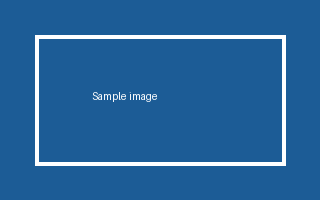

In [6]:
if pillow_available:
    with Image.open(generated_image_path) as img:
        print("Format:", img.format)
        print("Size (width, height):", img.size)
        print("Mode:", img.mode)
        display(img)

## 7. Resize and convert an image

`resize()` returns a new image. `convert("L")` produces an 8-bit grayscale image. Save to a new path so the original remains available. When changing formats, Pillow converts pixel data and encodes a new file; it is not a byte-for-byte copy.

Resized: c:\Users\ashir\OneDrive\Desktop\Mirai\AKTU\Python\File_handling\binary_media_data\sample_image_resized.png
Grayscale: c:\Users\ashir\OneDrive\Desktop\Mirai\AKTU\Python\File_handling\binary_media_data\sample_image_grayscale.png


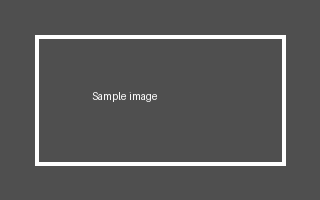

In [7]:
if pillow_available:
    resized_path = DATA_DIR / "sample_image_resized.png"
    grayscale_path = DATA_DIR / "sample_image_grayscale.png"
    with Image.open(generated_image_path) as img:
        resized = img.resize((160, 100))
        resized.save(resized_path)
        grayscale = img.convert("L")
        grayscale.save(grayscale_path)
    print("Resized:", resized_path)
    print("Grayscale:", grayscale_path)
    with Image.open(grayscale_path) as gray:
        display(gray)

## 8. Audio (songs): copy, inspect, and decode

A song file can be copied exactly with binary mode. Playing a song, reading its duration, or changing its volume requires understanding its audio codec/container. For metadata, the optional `mutagen` package supports many formats (`python -m pip install mutagen`). This example is guarded so the notebook continues if it is not installed.

Never assume a file extension proves the actual format. A `.mp3` name is a label; media tools inspect the contents.

In [8]:
AUDIO_PATH = Path("sample.mp3")  # Set this to a real audio file.

if AUDIO_PATH.exists():
    print("Audio file size:", AUDIO_PATH.stat().st_size, "bytes")
    try:
        from mutagen import File as MutagenFile
    except ImportError:
        print("For metadata, install optional Mutagen: python -m pip install mutagen")
    else:
        audio = MutagenFile(AUDIO_PATH)
        if audio is None:
            print("Mutagen could not identify this file's audio format.")
        else:
            print("Audio metadata:", audio.info)
            print("Duration (seconds):", getattr(audio.info, "length", None))
else:
    print("Set AUDIO_PATH to a real MP3/WAV/other supported audio file to inspect it.")

Set AUDIO_PATH to a real MP3/WAV/other supported audio file to inspect it.


### Playing audio in a notebook

Some notebook environments can play audio inline with IPython. The following display works for compatible local files; it does not convert unsupported codecs.

In [9]:
if AUDIO_PATH.exists():
    from IPython.display import Audio, display
    display(Audio(filename=str(AUDIO_PATH)))
else:
    print("Add an audio file at AUDIO_PATH to play it here.")

Add an audio file at AUDIO_PATH to play it here.


## 9. Video: copy and inspect with a media library

A video is usually a container holding compressed video and possibly audio streams. Binary copying preserves it exactly. To inspect frames or decode video, use a media tool such as OpenCV (optional: `python -m pip install opencv-python`). OpenCV decodes frames; it does not preserve original encoding when you write processed output. Production transcoding often uses FFmpeg.

This example reads a frame only when a file exists and OpenCV is installed.

In [10]:
VIDEO_PATH = Path("sample.mp4")  # Set this to a real video file.

if VIDEO_PATH.exists():
    print("Video file size:", VIDEO_PATH.stat().st_size, "bytes")
    try:
        import cv2
    except ImportError:
        print("To inspect frames, install optional OpenCV: python -m pip install opencv-python")
    else:
        capture = cv2.VideoCapture(str(VIDEO_PATH))
        if not capture.isOpened():
            print("Could not open/decode this video. Check its format and codec support.")
        else:
            fps = capture.get(cv2.CAP_PROP_FPS)
            frame_count = capture.get(cv2.CAP_PROP_FRAME_COUNT)
            width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
            height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
            duration = frame_count / fps if fps else None
            print({"width": width, "height": height, "fps": fps,
                   "frames": frame_count, "duration_seconds": duration})
            ok, frame_bgr = capture.read()
            if ok:
                from PIL import Image
                frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
                display(Image.fromarray(frame_rgb))
            capture.release()
else:
    print("Set VIDEO_PATH to a real MP4/other supported video file to inspect it.")

Set VIDEO_PATH to a real MP4/other supported video file to inspect it.


## 10. Raw bytes are not media decoding

These tools solve different problems:

| Task | Suitable approach |
|---|---|
| Copy any file unchanged | `rb` + `wb`, or `shutil.copyfile()` |
| Verify copied bytes | Compare SHA-256 digests |
| Display / resize / grayscale an image | Pillow (`Image.open`, `resize`, `convert`) |
| Read audio metadata / decode audio | A format-aware audio library such as Mutagen (metadata) or an audio decoder |
| Inspect / process video frames | OpenCV or FFmpeg |
| Play media | A player or notebook media display that supports its codec |

Changing bytes arbitrarily can corrupt a media file. A binary file handle only exposes raw data; it does not understand pixels, samples, frames, codecs, or containers.

## 11. Common mistakes and safe practices

- Use `rb`/`wb` for binary files; do not decode arbitrary file bytes as text.
- Do not load a huge media file with one `read()`; stream in chunks for copies and hashes.
- Remember that `wb` replaces the destination.
- Keep the source and destination distinct.
- Use Pillow for image operations; use audio/video-aware tools for those formats.
- Install optional packages in the same Python environment as the notebook kernel.
- Keep file paths explicit and check that the source exists.

## 12. Summary and practice

1. What is the difference between `str` and `bytes`?
2. Why does chunked copying use less memory?
3. Which Pillow call returns image dimensions? Which one resizes?
4. Why can copying an MP4 successfully still fail to play on another machine?
5. Adapt `copy_binary_file()` to copy your own song or video and verify its hash.
6. If Pillow is installed, open a real photo and save a resized copy as a new file.